# Guardia condicional contra aliasing de área
## Resumen
Dos aproximaciones iguales no prueban convergencia: cuatro de ocho casos deterministas se estancan falsamente en área cero. Una cota de velocidad externa permite certificar correctamente ocho signos; no elimina toda incertidumbre de área.
## Contexto y método
Para una curva planar $L$-Lipschitz en tiempos conocidos y muestras $x_i$, sea $A_P$ el área del polígono, cerrado por la cuerda final. En cada arco, trasladar origen a $x_i$ anula la contribución de su cuerda y acota el error por $\frac12(L\Delta t_i)^2$. Así:
$$|A-A_P|\leq B=\frac{L^2}{2}\sum_i(\Delta t_i)^2.$$
Signo positivo si $A_P>B$, negativo si $A_P<-B$; de lo contrario abstención y refinamiento.
### Supuestos clave
$L$ es una cota **conocida externa**, no el máximo de pendientes observadas. Comprobar secantes es necesario pero no suficiente. Cota analítica en aritmética exacta; floats no usan redondeo dirigido, por lo que no se afirma certificación formal intervalar de máquina.
## Datos
Círculos sintéticos con 1,2,4,8 vueltas y dos orientaciones. Analítica $A=\pm\pi k$, $L=2\pi k$. Semilla 20261024; 200 grillas irregulares; sin datos operativos.

In [1]:
import csv, json
from pathlib import Path
from IPython.display import display, Image
config=json.loads(Path('config_guard.json').read_text())
summary=json.loads(Path('results/guard_summary.json').read_text())
config

Out[0]: 
{'seed': 20261024,
 'turns': [1, 2, 4, 8],
 'max_segments': 4096,
 'plateau_tolerance': 1e-10,
 'irregular_trials': 200,
 'hypothesis': 'all continuous-area signs certified with correct L agree with analytic truth; plateau false stopping occurs on aliased loops',
 'speed_assumption': 'known Euclidean speed upper bound L=2*pi*turns on [0,1]'}


## Resultados
La comparación usa tres reglas distintas: presupuesto fijo, meseta y cota. No se comparan como si ofrecieran la misma garantía. Certificar signo puede dejar error de área considerable.

In [2]:
summary

Out[0]: 
{'seed': 20261024,
 'cases': 8,
 'methods': {'fixed8': {'wrong_signs': 0,
   'abstentions': 4,
   'max_area_error': 25.132741228718345,
   'mean_final_segments': 8.0,
   'total_seconds': 0.0013373099999967053},
  'plateau': {'wrong_signs': 0,
   'abstentions': 4,
   'max_area_error': 25.132741228718345,
   'mean_final_segments': 2052.0,
   'total_seconds': 0.008069447999844215},
  'certified': {'wrong_signs': 0,
   'abstentions': 0,
   'max_area_error': 2.5053242307488297,
   'mean_final_segments': 30.0,
   'total_seconds': 0.005940504000022884},
  'certified_budget8': {'wrong_signs': 0,
   'abstentions': 6,
   'max_area_error': 25.132741228718345,
   'mean_final_segments': 8.0,
   'total_seconds': 0.0033030180000537257}},
 'plateau_false_convergence': 4,
 'irregular_trials': 200,
 'irregular_enclosed': 200,
 'irregular_wrong_sign': 0,
 'irregular_certified': 114,
 'python': '3.12.14',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39',
 'invalid_bound_counterexample': {'suppl

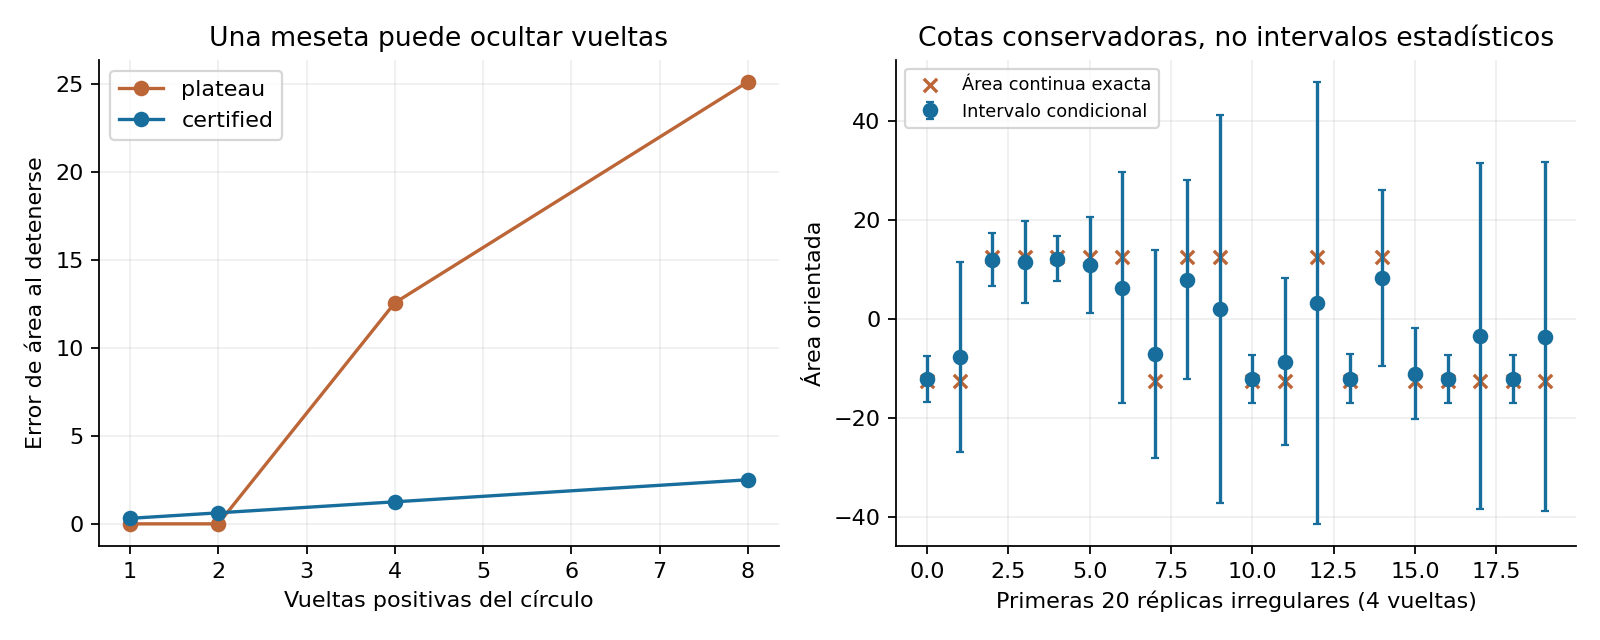

In [3]:
display(Image(filename='results/guard_audit.png'))

### Resultados crudos y recursos
El CSV guarda tiempo y pico Python tracemalloc por ejecución. Segmentos finales no equivalen al total de evaluaciones: el prototipo reevalúa todos los nodos tras duplicar.

In [4]:
rows=list(csv.DictReader(Path('results/guard_comparison.csv').open()))
[{k:r[k] for k in ['turns','orientation','method','segments','area_error','seconds','peak_python_bytes']} for r in rows if r['orientation']=='1']

Out[0]: 
[{'turns': '1',
  'orientation': '1',
  'method': 'fixed8',
  'segments': '8',
  'area_error': '0.31316552884360327',
  'seconds': '0.0001376069999992069',
  'peak_python_bytes': '8288'},
 {'turns': '1',
  'orientation': '1',
  'method': 'plateau',
  'segments': '4096',
  'area_error': '1.2320785929276212e-06',
  'seconds': '0.0019112349999659273',
  'peak_python_bytes': '200040'},
 {'turns': '1',
  'orientation': '1',
  'method': 'certified',
  'segments': '8',
  'area_error': '0.31316552884360327',
  'seconds': '0.0004713390000006257',
  'peak_python_bytes': '9160'},
 {'turns': '1',
  'orientation': '1',
  'method': 'certified_budget8',
  'segments': '8',
  'area_error': '0.31316552884360327',
  'seconds': '0.0004053300000350646',
  'peak_python_bytes': '9136'},
 {'turns': '2',
  'orientation': '1',
  'method': 'fixed8',
  'segments': '8',
  'area_error': '2.2831853071795862',
  'seconds': '0.00013132700001960984',
  'peak_python_bytes': '8224'},
 {'turns': '2',
  'orientati

## Pruebas y caso negativo
Un L falso puede pasar la prueba de secantes y producir signo erróneo. Esto refuta la idea de aprender una garantía global de muestras finitas sin supuestos.

In [5]:
from src.aliasing_guard import certify_area
from src.benchmark_guard import curve
import numpy as np
t=np.linspace(0,1,9)
false=certify_area(curve(t,7,1),t,6.2)
assert false.sign==-1
assert summary['irregular_enclosed']==config['irregular_trials']
assert summary['methods']['certified']['abstentions']==0
assert summary['methods']['certified']['wrong_signs']==0
print('Supuesto falso:',false)
print('Área real:',7*np.pi)

Supuesto falso: Certificate(area=-2.82842712474619, radius=2.4025000000000003, sign=-1, segments=8)
Área real: 21.991148575128552


## Conclusiones
El guardia corrige la política de parada en estos casos y evita confundir estabilidad entre mallas con resolución. Con presupuesto ocho se abstiene seis veces; bajo L falso puede fallar. Madurez S2, sin promoción a validación externa. Referencias primarias verificadas en fuentes_guard.md; informe_guard.md contiene derivación y 14 puntos.